<a href="https://colab.research.google.com/github/munnamia1945/AI_ML_DL_class_practice/blob/main/Assignment_08_Brain_tumor_CNN_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Import standard libraries

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, load_img
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.20.0


# Path setup

In [ ]:
dataset_dir = '/content/drive/MyDrive/Colab Notebooks/Lab7/brain_tumor_dataset' # Modify path as needed
no_dir = os.path.join(dataset_dir, 'no')
yes_dir = os.path.join(dataset_dir, 'yes')

# NO. of current image check

In [ ]:
no_images = os.listdir(no_dir)
yes_images = os.listdir(yes_dir)
print(f"Original 'no' images count: {len(no_images)}")
print(f"Original 'yes' images count: {len(yes_images)}")

Original 'no' images count: 98
Original 'yes' images count: 155


# target: 'no' make 155 image on this class

In [ ]:
target_count = len(yes_images)  # 155
current_no_count = len(no_images) # 98
needed_aug = target_count - current_no_count # 57 images needed


# Data Augmentation Generator Setup

In [ ]:
datagen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Generate augmented images for 'no' class

In [ ]:
print(f"\nGenerating {needed_aug} augmented images for 'no' class...")
aug_created = 0

while aug_created < needed_aug:
    for img_name in no_images:
        if aug_created >= needed_aug:
            break
        img_path = os.path.join(no_dir, img_name)
        img = load_img(img_path)
        x = img_to_array(img)
        x = np.expand_dims(x, axis=0)

        for batch in datagen.flow(x, batch_size=1, save_to_dir=no_dir, save_prefix='aug_no', save_format='jpeg'):
            aug_created += 1
            break

print(f"Augmentation Complete! Total 'no' images now: {len(os.listdir(no_dir))}")





IMG_SIZE = 128
data = []
labels = []


Generating 57 augmented images for 'no' class...
Augmentation Complete! Total 'no' images now: 155


# Load 'no' images (label 0)

In [ ]:
for img_name in os.listdir(no_dir):
    try:
        img_path = os.path.join(no_dir, img_name)
        img = cv2.imread(img_path)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        data.append(img)
        labels.append(0)
    except Exception as e:
        pass

# Load 'yes' images (label 1)

In [ ]:
for img_name in os.listdir(yes_dir):
    try:
        img_path = os.path.join(yes_dir, img_name)
        img = cv2.imread(img_path)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        data.append(img)
        labels.append(1)
    except Exception as e:
        pass

X = np.array(data, dtype='float32') / 255.0  # Normalization
y = np.array(labels)

print(f"Total dataset shape: {X.shape}")
print(f"Total labels shape: {y.shape}")


Total dataset shape: (310, 128, 128, 3)
Total labels shape: (310,)


# Train-Test Split (80% Train, 20% Test)

Train samples: 248, Test samples: 62


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 13s 718ms/step - accuracy: 0.6492 - loss: 0.6762 - val_accuracy: 0.6774 - val_loss: 0.6162
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 20s 686ms/step - accuracy: 0.7702 - loss: 0.5017 - val_accuracy: 0.7097 - val_loss: 0.5519
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 18s 564ms/step - accuracy: 0.7863 - loss: 0.4877 - val_accuracy: 0.7097 - val_loss: 0.5656
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 11s 565ms/step - accuracy: 0.8427 - loss: 0.4139 - val_accuracy: 0.7097 - val_loss: 0.6952
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 12s 695ms/step - accuracy: 0.8226 - loss: 0.3913 - val_accuracy: 0.7258 - val_loss: 0.5391
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 494ms/step - accuracy: 0.8629 - loss: 0.3386 - val_accuracy: 0.7419 - val_loss: 0.6138
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 10s 644ms/step - accuracy: 0.8952 - loss: 0.2694 - val_accuracy: 0.8065 - val_loss: 0.5422
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 18s 494ms/step - accuracy: 0.8831 - loss: 0.2402 - val_accur

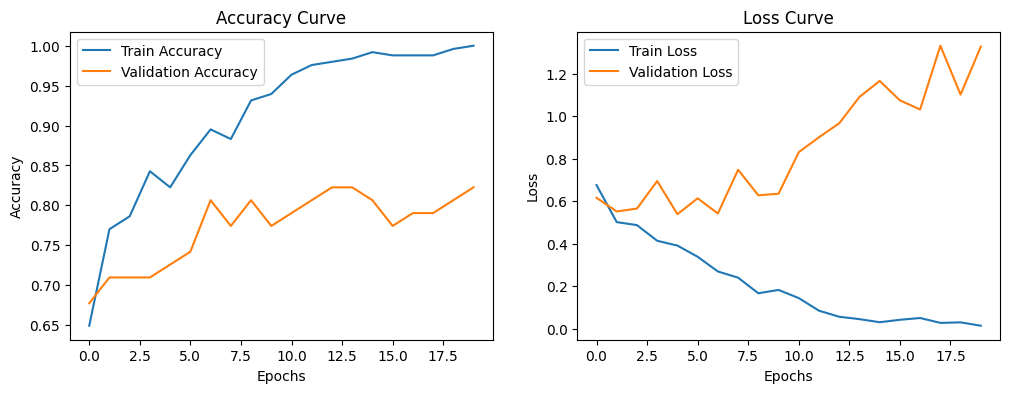

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 510ms/step


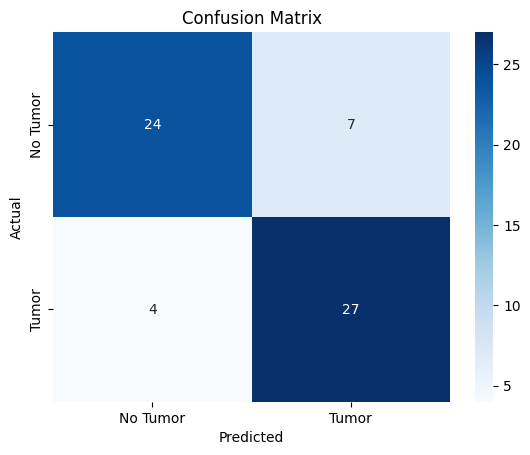


Classification Report:

              precision    recall  f1-score   support

No Tumor (0)       0.86      0.77      0.81        31
   Tumor (1)       0.79      0.87      0.83        31

    accuracy                           0.82        62
   macro avg       0.83      0.82      0.82        62
weighted avg       0.83      0.82      0.82        62

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


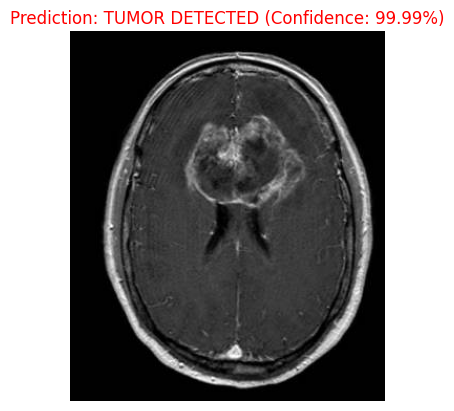

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print(f"Train samples: {len(X_train)}, Test samples: {len(X_test)}")




model = Sequential([
    # Block 1
    Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    MaxPooling2D((2, 2)),

    # Block 2
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # Block 3
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # Classification Head
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),  # Prevents Overfitting
    Dense(1, activation='sigmoid')  # Binary Output (0 or 1)
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()



EPOCHS = 20
BATCH_SIZE = 16

history = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_test, y_test)
)








# 1. Accuracy and Loss Plots
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

# 2. Confusion Matrix & Classification Report
y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int)

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Tumor', 'Tumor'], yticklabels=['No Tumor', 'Tumor'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=['No Tumor (0)', 'Tumor (1)']))




def predict_mri(image_path):
    img = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    img_resized = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    img_normalized = img_resized.astype('float32') / 255.0
    img_input = np.expand_dims(img_normalized, axis=0)

    prediction = model.predict(img_input)[0][0]

    plt.imshow(img_rgb)
    plt.axis('off')
    if prediction > 0.5:
        plt.title(f"Prediction: TUMOR DETECTED (Confidence: {prediction*100:.2f}%)", color='red', fontsize=12)
    else:
        plt.title(f"Prediction: NO TUMOR (Confidence: {(1-prediction)*100:.2f}%)", color='green', fontsize=12)
    plt.show()

# ড্রাইভ থেকে যেকোনো একটি ছবি দিয়ে টেস্ট করে দেখুন
sample_img_path = os.path.join(yes_dir, os.listdir(yes_dir)[0]) # Example test
predict_mri(sample_img_path)
